# Customer Churn Prediction & Analysis

**Project Overview**

Customer churn is an important business problem for telecom companies because
retaining existing customers can be more cost-effective than acquiring new ones.

In this project, machine learning techniques are used to predict customer churn
and identify customer characteristics associated with churn risk.

The project covers:

- Data cleaning and preprocessing
- Exploratory data analysis
- Feature engineering and selection
- Classification model development
- Hyperparameter tuning
- Model evaluation
- Model interpretation
- Business insights

## 1. Data Understanding & Cleaning

In [170]:
import pandas as pd 
import numpy as np 

df = pd.read_excel("../data/raw/Telco_customer_churn.xlsx")

### 1.1.Checking missing values and data types

In [171]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   str    
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   str    
 3   State              7043 non-null   str    
 4   City               7043 non-null   str    
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   str    
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   str    
 10  Senior Citizen     7043 non-null   str    
 11  Partner            7043 non-null   str    
 12  Dependents         7043 non-null   str    
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   str    
 15  Multiple Lines     7043 non-null   str    
 16  Internet Service   7043 non-null   

In [172]:
df.isnull().sum()

CustomerID              0
Count                   0
Country                 0
State                   0
City                    0
Zip Code                0
Lat Long                0
Latitude                0
Longitude               0
Gender                  0
Senior Citizen          0
Partner                 0
Dependents              0
Tenure Months           0
Phone Service           0
Multiple Lines          0
Internet Service        0
Online Security         0
Online Backup           0
Device Protection       0
Tech Support            0
Streaming TV            0
Streaming Movies        0
Contract                0
Paperless Billing       0
Payment Method          0
Monthly Charges         0
Total Charges           0
Churn Label             0
Churn Value             0
Churn Score             0
CLTV                    0
Churn Reason         5174
dtype: int64

### 1.2. Missing Value Analysis

Almost all variables contain no missing values. Churn Reason contains
5,174 missing values because this information is only available for
customers who churned.

Churn Reason will be excluded from the machine learning features because
it is known only after churn occurs and would cause data leakage.

Dropping Columns

In [173]:
drop_cols = [
    "CustomerID",
    "Churn Reason",
    "Churn Value",
    "Churn Score",
    "Count",
    "Country",
    "State",
    "City",
    "Zip Code",
    "Lat Long",
    "Latitude",
    "Longitude"
]

df_model = df.drop(columns = drop_cols)

In [174]:
df_model.columns

Index(['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months',
       'Phone Service', 'Multiple Lines', 'Internet Service',
       'Online Security', 'Online Backup', 'Device Protection', 'Tech Support',
       'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing',
       'Payment Method', 'Monthly Charges', 'Total Charges', 'Churn Label',
       'CLTV'],
      dtype='str')

In [175]:
df_model["Total Charges"] = df_model["Total Charges"].fillna(0)

In [176]:
df_model["Total Charges"].isnull().sum()

np.int64(0)

## 2. Feature Preparation

In [177]:
X = df_model.drop(columns=["Churn Label"]) # Input Features
y = df_model["Churn Label"]                # Target/Output Features

In [178]:
X.shape

(7043, 20)

In [179]:
y.shape

(7043,)

### 2.1. Split the Data

In [180]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [181]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(5634, 20)
(1409, 20)
(5634,)
(1409,)


### 2.2. Separating Numerical and Categorical Columns

In [182]:
categorical_cols = X_train.select_dtypes(include = ["str", "object"]).columns

numerical_cols = X_train.select_dtypes(include = ["int64","float64"]).columns

print(categorical_cols)
print(numerical_cols)

Index(['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service',
       'Multiple Lines', 'Internet Service', 'Online Security',
       'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV',
       'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method',
       'Total Charges'],
      dtype='str')
Index(['Tenure Months', 'Monthly Charges', 'CLTV'], dtype='str')


Problem: Total Charges

Total Charges should be numerical, but it's being detected as a string (str).

This happened because earlier the column contained blank values and was originally stored as text.

We filled the missing values with 0, but we didn't explicitly convert the column back to numeric.

In [183]:
# Fix

df_model["Total Charges"] = pd.to_numeric(
    df_model["Total Charges"], 
    errors = "coerce"
)



In [184]:
df_model["Total Charges"].dtype

dtype('float64')

Because we created X_train and X_test before fixing the dtype, they still contain the old version of Total Charges.

Hence we make model again

In [185]:
X = df_model.drop(columns=["Churn Label"])
y = df_model["Churn Label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


print(X_train.shape)
print(X_test.shape)

(5634, 20)
(1409, 20)


In [186]:
categorical_cols = X_train.select_dtypes(include = ["str", "object"]).columns

numerical_cols = X_train.select_dtypes(include = ["int64","float64"]).columns

print(categorical_cols)
print(numerical_cols)

Index(['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service',
       'Multiple Lines', 'Internet Service', 'Online Security',
       'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV',
       'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method'],
      dtype='str')
Index(['Tenure Months', 'Monthly Charges', 'Total Charges', 'CLTV'], dtype='str')


## 3. Data Preprocessing

#### 3.1. Categorical Encoding

Categorical variables were converted into numerical representations using one-hot encoding. handle_unknown="ignore" ensures that unseen categories during testing do not cause transformation errors.

In [187]:
# Import the tools

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

In [188]:
# Create the encoder

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
        ("num", "passthrough", numerical_cols)
    ]
)

In [189]:
# Fit and transform the training data

X_train_encoded = preprocessor.fit_transform(X_train)

'''
Because we need to learn the encoding from the 
training data and then encode the training data.
'''


'\nBecause we need to learn the encoding from the \ntraining data and then encode the training data.\n'

This will:

1. Learn the categories from X_train
2. One-hot encode the 16 categorical columns
3. Keep the 4 numerical columns unchanged

In [190]:
X_test_encoded = preprocessor.transform(X_test)

'''
Because the test set is unseen data.
'''

'\nBecause the test set is unseen data.\n'

In [191]:
print(X_train_encoded.shape)
print(X_test_encoded.shape)

(5634, 47)
(1409, 47)


Why did 20 become 47?

We had:
4 numerical columns → remain 4 columns

16 categorical columns → each category becomes its own binary column

#### 3.3. Combined Preprocessor

In [192]:
preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
        ("num", StandardScaler(), numerical_cols)
    ]
)

In [193]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

Why this version?

| Feature type | What we do     | Why                                            |
| ------------ | -------------- | ---------------------------------------------- |
| Categorical  | One-hot encode | Converts categories into numerical columns     |
| Numerical    | StandardScaler | Puts numerical variables on a comparable scale |


In [194]:
print(X_train_processed.shape)
print(X_test_processed.shape)

(5634, 47)
(1409, 47)


## 4. Baseline Models

### 4.1 Logistic Regression

Logistic Regression was used as a baseline linear classification model for predicting customer churn.

In [195]:
from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression(max_iter=1000)

#### Train the model

In [196]:
# log_model.fit(X_train_processed, y_train)

Why did this happen?

Earlier we checked missing values in the original dataset and found Churn Reason missing, which we intentionally removed.

But after converting any values that couldn't be converted became NaN.

In [197]:
X_train.isna().sum()[X_train.isna().sum() > 0]

Total Charges    8
dtype: int64

In [198]:
X_train.isna().sum().sum()

np.int64(8)

In [199]:
X_train.loc[
    X_train["Total Charges"].isna(),
    ["Tenure Months", "Total Charges"]
]

,Tenure Months,Total Charges
6772,0,NaN
5104,0,NaN
4687,0,NaN
2234,0,NaN
2667,0,NaN
2856,0,NaN
6840,0,NaN
4331,0,NaN


In [200]:
X_train["Total Charges"] = X_train["Total Charges"].fillna(0)
X_test["Total Charges"] = X_test["Total Charges"].fillna(0)

print(X_train["Total Charges"].isna().sum())
print(X_test["Total Charges"].isna().sum())

0
0


In [201]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print(X_train_processed.shape)
print(X_test_processed.shape)

(5634, 47)
(1409, 47)


In [202]:
log_model = LogisticRegression(max_iter=1000)

log_model.fit(X_train_processed, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is '

#### Make predictions

In [203]:
y_pred = log_model.predict(X_test_processed)

y_pred[:10]

array(['No', 'Yes', 'No', 'No', 'No', 'Yes', 'No', 'No', 'No', 'No'],
      dtype=object)

#### Get churn probabilities

In [204]:
y_proba = log_model.predict_proba(X_test_processed)

y_proba[:10]

array([[0.92401886, 0.07598114],
       [0.32135041, 0.67864959],
       [0.90146445, 0.09853555],
       [0.53174146, 0.46825854],
       [0.96938961, 0.03061039],
       [0.38843227, 0.61156773],
       [0.52774682, 0.47225318],
       [0.95980402, 0.04019598],
       [0.99887934, 0.00112066],
       [0.61419522, 0.38580478]])

The first column is probability of No, and the second column is probability of Yes.

For a customer-churn project, probabilities are often more informative than just Yes/No because you can identify customers who are:

High risk → 80–90% churn probability

Medium risk → around 40–60%

Low risk → 10–20%

We'll use these probabilities later when discussing model evaluation and business interpretation.

#### Now we evaluate the model

In [205]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.8019872249822569


Accuracy tells us how many predictions were correct overall. It does not tell us whether the model is actually good at detecting churners.

We still don't know:

How many actual churners did we correctly identify? → True Positives

How many churners did we miss? → False Negatives

How many non-churners did we incorrectly flag? → False Positives

That's what we'll see next.

#### Confusion Matrix

In [206]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[916 119]
 [160 214]]


|                | **Predicted No** | **Predicted Yes** |
| -------------- | ---------------: | ----------------: |
| **Actual No**  |          **916** |           **119** |
| **Actual Yes** |          **160** |           **214** |

The model correctly identified 916 customers who did not churn.

The model incorrectly flagged 119 customers as likely to churn. 
Think of this as a false alarm.

**The model missed 160 customers who actually churned. This is particularly important in a churn problem because these are customers the model failed to identify as churn risks.**

The model correctly identified 214 customers who actually churned.

What percentage of actual churners did our model successfully identify?

In [207]:
from sklearn.metrics import recall_score

recall = recall_score(y_test, y_pred, pos_label="Yes")

print("Recall:", recall)

Recall: 0.5721925133689839


#### Precision

Precision answers:

Of all the customers our model predicted would churn, how many actually churned?

In [208]:
from sklearn.metrics import precision_score

precision = precision_score(y_test, y_pred, pos_label="Yes")

print("Precision:", precision)

Precision: 0.6426426426426426


#### F1-score

We can combine precision and recall into a single metric called the F1-score:
 
It gives a balance between precision and recall.

In [209]:
from sklearn.metrics import f1_score

f1 = f1_score(y_test, y_pred, pos_label="Yes")

print("F1 Score:", f1)

F1 Score: 0.6053748231966054


| Metric        |     Result | What it tells us                         |
| ------------- | ---------: | ---------------------------------------- |
| **Accuracy**  | **80.20%** | Overall correct predictions              |
| **Precision** | **64.26%** | When predicting churn, how often correct |
| **Recall**    | **57.22%** | Actual churners successfully detected    |
| **F1-score**  | **60.54%** | Balance of precision and recall          |


#### Classification Report

Rather than calculating each metric separately, sklearn can give us the complete report in one place.

In [210]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

          No       0.85      0.89      0.87      1035
         Yes       0.64      0.57      0.61       374

    accuracy                           0.80      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.80      0.80      1409



### 4.2 Decision Tree

In [211]:
from sklearn.tree import DecisionTreeClassifier

tree_model = DecisionTreeClassifier(random_state=42)

tree_model.fit(X_train_processed, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples 

In [212]:
y_pred_tree = tree_model.predict(X_test_processed)

y_pred_tree[:10]

array(['No', 'Yes', 'No', 'Yes', 'No', 'Yes', 'Yes', 'No', 'No', 'Yes'],
      dtype=object)

In [213]:
from sklearn.metrics import accuracy_score

accuracy_tree = accuracy_score(y_test, y_pred_tree)

print("Decision Tree Accuracy:", accuracy_tree)

Decision Tree Accuracy: 0.7210787792760823


In [214]:
from sklearn.metrics import confusion_matrix

cm_tree = confusion_matrix(y_test, y_pred_tree)

print(cm_tree)

[[831 204]
 [189 185]]


In [215]:
from sklearn.metrics import recall_score

recall_tree = recall_score(
    y_test,
    y_pred_tree,
    pos_label="Yes"
)

print("Decision Tree Recall:", recall_tree)

Decision Tree Recall: 0.4946524064171123


In [216]:
from sklearn.metrics import precision_score

precision_tree = precision_score(
    y_test,
    y_pred_tree,
    pos_label="Yes"
)

print("Decision Tree Precision:", precision_tree)

Decision Tree Precision: 0.4755784061696658


In [217]:
from sklearn.metrics import f1_score

f1_tree = f1_score(
    y_test,
    y_pred_tree,
    pos_label="Yes"
)

print("Decision Tree F1 Score:", f1_tree)

Decision Tree F1 Score: 0.4849279161205767


In [218]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_tree))

              precision    recall  f1-score   support

          No       0.81      0.80      0.81      1035
         Yes       0.48      0.49      0.48       374

    accuracy                           0.72      1409
   macro avg       0.65      0.65      0.65      1409
weighted avg       0.72      0.72      0.72      1409



### 4.3 Random Forest

A Random Forest is essentially an ensemble of many Decision Trees. Instead of relying on one tree, it builds multiple trees and combines their predictions.

In [219]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

In [220]:
rf_model.fit(X_train_processed, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [221]:
y_pred_rf = rf_model.predict(X_test_processed)

y_pred_rf[:10]

array(['No', 'Yes', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No'],
      dtype=object)

In [222]:
from sklearn.metrics import accuracy_score

accuracy_rf = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", accuracy_rf)

Random Forest Accuracy: 0.7913413768630234


In [223]:
from sklearn.metrics import confusion_matrix

cm_rf = confusion_matrix(y_test, y_pred_rf)

print(cm_rf)

[[924 111]
 [183 191]]


In [224]:
from sklearn.metrics import recall_score

recall_rf = recall_score(
    y_test,
    y_pred_rf,
    pos_label="Yes"
)

print("Random Forest Recall:", recall_rf)

Random Forest Recall: 0.5106951871657754


In [225]:
from sklearn.metrics import precision_score

precision_rf = precision_score(
    y_test,
    y_pred_rf,
    pos_label="Yes"
)

print("Random Forest Precision:", precision_rf)

Random Forest Precision: 0.6324503311258278


In [226]:
from sklearn.metrics import f1_score

f1_rf = f1_score(
    y_test,
    y_pred_rf,
    pos_label="Yes"
)

print("Random Forest F1 Score:", f1_rf)

Random Forest F1 Score: 0.5650887573964497


In [227]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

          No       0.83      0.89      0.86      1035
         Yes       0.63      0.51      0.57       374

    accuracy                           0.79      1409
   macro avg       0.73      0.70      0.71      1409
weighted avg       0.78      0.79      0.78      1409



### 4.4. Baseline Models Comparison

| Metric              | Logistic Regression | Decision Tree | Random Forest |
| ------------------- | ------------------: | ------------: | ------------: |
| **Accuracy**        |          **80.20%** |        72.11% |        79.13% |
| **Churn Precision** |          **64.26%** |        47.56% |        63.25% |
| **Churn Recall**    |          **57.22%** |        49.47% |        51.07% |
| **Churn F1**        |          **60.54%** |        48.49% |        56.51% |


## 5. Hyperparameter Tuning

### 5.1. Decision Tree

Hyperparameter tuning = trying different settings to find a model configuration that generalizes well to unseen data.

max_depth = Controls the maximum depth of the tree.

min_samples_split = Minimum number of observations required before a node can be split.

In [228]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "max_depth": [3, 5, 7, 10, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 5]
}

tree = DecisionTreeClassifier(random_state=42)

grid_search_tree = GridSearchCV(
    estimator=tree,
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

grid_search_tree.fit(X_train_processed, y_train)

c:\Users\markr\Desktop\Git\customer-churn-prediction\venv\Lib\site-packages\sklearn\model_selection\_search.py:1234: UserWarning: One or more of the test scores are non-finite: [nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan
 nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan
 nan nan nan nan nan nan nan nan nan]
  warnings.warn(


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [3, 5, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Contr

In [229]:
from sklearn.metrics import make_scorer, f1_score
from sklearn.model_selection import GridSearchCV

f1_yes = make_scorer(
    f1_score,
    pos_label="Yes"
)

grid_search_tree = GridSearchCV(
    estimator=tree,
    param_grid=param_grid,
    cv=5,
    scoring=f1_yes,
    n_jobs=-1
)

grid_search_tree.fit(X_train_processed, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [3, 5, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",make_scorer(f...pos_label=Yes)
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose ve

In [230]:
print("Best Parameters:", grid_search_tree.best_params_)
print("Best Cross-Validation F1:", grid_search_tree.best_score_)

Best Parameters: {'max_depth': 7, 'min_samples_leaf': 2, 'min_samples_split': 5}
Best Cross-Validation F1: 0.5809067173990858


In [231]:
best_tree = grid_search_tree.best_estimator_

y_pred_tree_tuned = best_tree.predict(X_test_processed)

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("Accuracy:", accuracy_score(y_test, y_pred_tree_tuned))
print("Precision:", precision_score(y_test, y_pred_tree_tuned, pos_label="Yes"))
print("Recall:", recall_score(y_test, y_pred_tree_tuned, pos_label="Yes"))
print("F1 Score:", f1_score(y_test, y_pred_tree_tuned, pos_label="Yes"))

Accuracy: 0.7821149751596878
Precision: 0.6037151702786377
Recall: 0.5213903743315508
F1 Score: 0.5595408895265424


So tuning substantially improved the Decision Tree.

The particularly important improvement is precision: the original tree's churn predictions were correct about 48% of the time, while the tuned tree's were correct about 60% of the time.

#### Pipeline Creation

Ideally, preprocessing should happen inside a Pipeline, so each cross-validation fold learns its own scaling/encoding parameters.

In [232]:
from sklearn.pipeline import Pipeline

tree_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeClassifier(random_state=42))
])

param_grid_pipeline = {
    "model__max_depth": [3, 5, 7, 10, None],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 5]
}

grid_tree_pipeline = GridSearchCV(
    estimator=tree_pipeline,
    param_grid=param_grid_pipeline,
    cv=5,
    scoring=f1_yes,
    n_jobs=-1
)

grid_tree_pipeline.fit(X_train, y_train)

print("Best Parameters:", grid_tree_pipeline.best_params_)
print("Best CV F1:", grid_tree_pipeline.best_score_)

Best Parameters: {'model__max_depth': 7, 'model__min_samples_leaf': 2, 'model__min_samples_split': 5}
Best CV F1: 0.5811120510347509


In [233]:
y_pred_tree_pipeline = grid_tree_pipeline.predict(X_test)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("Accuracy:", accuracy_score(y_test, y_pred_tree_pipeline))
print("Precision:", precision_score(
    y_test,
    y_pred_tree_pipeline,
    pos_label="Yes"
))
print("Recall:", recall_score(
    y_test,
    y_pred_tree_pipeline,
    pos_label="Yes"
))
print("F1 Score:", f1_score(
    y_test,
    y_pred_tree_pipeline,
    pos_label="Yes"
))

Accuracy: 0.7821149751596878
Precision: 0.6037151702786377
Recall: 0.5213903743315508
F1 Score: 0.5595408895265424


### 5.2. Logistic Regression

In [234]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

log_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])

log_param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__class_weight": [None, "balanced"]
}

grid_log = GridSearchCV(
    estimator=log_pipeline,
    param_grid=log_param_grid,
    cv=5,
    scoring=f1_yes,
    n_jobs=-1
)

grid_log.fit(X_train, y_train)

print("Best Parameters:", grid_log.best_params_)
print("Best CV F1:", grid_log.best_score_)

Best Parameters: {'model__C': 0.1, 'model__class_weight': 'balanced'}
Best CV F1: 0.6427823270690303


In [235]:
y_pred_log_tuned = grid_log.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_log_tuned))

print("Precision:", precision_score(
    y_test,
    y_pred_log_tuned,
    pos_label="Yes"
))

print("Recall:", recall_score(
    y_test,
    y_pred_log_tuned,
    pos_label="Yes"
))

print("F1 Score:", f1_score(
    y_test,
    y_pred_log_tuned,
    pos_label="Yes"
))

Accuracy: 0.7437899219304471
Precision: 0.511504424778761
Recall: 0.7727272727272727
F1 Score: 0.6155484558040468


### 5.3. Random Forest

In [236]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(random_state=42))
])

rf_param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [5, 10, None],
    "model__min_samples_split": [2, 5],
    "model__min_samples_leaf": [1, 2],
    "model__class_weight": [None, "balanced"]
}

grid_rf = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_param_grid,
    cv=5,
    scoring=f1_yes,
    n_jobs=-1
)

grid_rf.fit(X_train, y_train)

print("Best Parameters:", grid_rf.best_params_)
print("Best CV F1:", grid_rf.best_score_)

Best Parameters: {'model__class_weight': 'balanced', 'model__max_depth': 10, 'model__min_samples_leaf': 1, 'model__min_samples_split': 5, 'model__n_estimators': 200}
Best CV F1: 0.6522921493948006


In [237]:
y_pred_rf_tuned = grid_rf.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_rf_tuned))

print("Precision:", precision_score(
    y_test,
    y_pred_rf_tuned,
    pos_label="Yes"
))

print("Recall:", recall_score(
    y_test,
    y_pred_rf_tuned,
    pos_label="Yes"
))

print("F1 Score:", f1_score(
    y_test,
    y_pred_rf_tuned,
    pos_label="Yes"
))

Accuracy: 0.7636621717530163
Precision: 0.5387523629489603
Recall: 0.7620320855614974
F1 Score: 0.6312292358803987


## 6. Additional Machine Learning Models

### 6.1. KNN

In [238]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV

knn_preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ), categorical_cols),

        ("num", StandardScaler(), numerical_cols)
    ]
)

knn_pipeline = Pipeline([
    ("preprocessor", knn_preprocessor),
    ("model", KNeighborsClassifier())
])

knn_param_grid = {
    "model__n_neighbors": [3, 5, 7, 11, 15],
    "model__weights": ["uniform", "distance"],
    "model__p": [1, 2]
}

f1_yes = make_scorer(f1_score, pos_label="Yes")

grid_knn = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=knn_param_grid,
    cv=5,
    scoring=f1_yes,
    n_jobs=-1
)

grid_knn.fit(X_train, y_train)

print("Best Parameters:", grid_knn.best_params_)
print("Best CV F1:", grid_knn.best_score_)

Best Parameters: {'model__n_neighbors': 15, 'model__p': 2, 'model__weights': 'uniform'}
Best CV F1: 0.6218984788784623


In [239]:
y_pred_knn = grid_knn.predict(X_test)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

accuracy_knn = accuracy_score(y_test, y_pred_knn)
precision_knn = precision_score(y_test, y_pred_knn, pos_label="Yes")
recall_knn = recall_score(y_test, y_pred_knn, pos_label="Yes")
f1_knn = f1_score(y_test, y_pred_knn, pos_label="Yes")

print("Accuracy:", accuracy_knn)
print("Precision:", precision_knn)
print("Recall:", recall_knn)
print("F1 Score:", f1_knn)

Accuracy: 0.78708303761533
Precision: 0.5989304812834224
Recall: 0.5989304812834224
F1 Score: 0.5989304812834224


In [240]:
cm_knn = confusion_matrix(
    y_test,
    y_pred_knn,
    labels=["No", "Yes"]
)

print(cm_knn)

[[885 150]
 [150 224]]


In [241]:
print(classification_report(y_test, y_pred_knn))

              precision    recall  f1-score   support

          No       0.86      0.86      0.86      1035
         Yes       0.60      0.60      0.60       374

    accuracy                           0.79      1409
   macro avg       0.73      0.73      0.73      1409
weighted avg       0.79      0.79      0.79      1409



KNN is actually interesting:

- Its accuracy is 78.71%, slightly higher than all three tuned models.

- Its precision is 59.89%, close to the tuned Decision Tree.

- Its recall is 59.89%, substantially lower than tuned Logistic Regression and Random Forest.

- Its F1 = 59.89%, so it doesn't surpass the current Random Forest on this metric.

### 6.2. Support Vector Machine (SVM)

In [242]:
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

svm_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", SVC(
        probability=True,
        random_state=42
    ))
])

svm_param_grid = {
    "model__C": [0.1, 1, 10],
    "model__kernel": ["linear", "rbf"],
    "model__gamma": ["scale", "auto"]
}

grid_svm = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=svm_param_grid,
    cv=5,
    scoring=f1_yes,
    n_jobs=-1
)

grid_svm.fit(X_train, y_train)

print("Best Parameters:", grid_svm.best_params_)
print("Best CV F1:", grid_svm.best_score_)

c:\Users\markr\Desktop\Git\customer-churn-prediction\venv\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Best Parameters: {'model__C': 10, 'model__gamma': 'scale', 'model__kernel': 'linear'}
Best CV F1: 0.6087408515945997


In [243]:
y_pred_svm = grid_svm.predict(X_test)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

accuracy_svm = accuracy_score(y_test, y_pred_svm)
precision_svm = precision_score(y_test, y_pred_svm, pos_label="Yes")
recall_svm = recall_score(y_test, y_pred_svm, pos_label="Yes")
f1_svm = f1_score(y_test, y_pred_svm, pos_label="Yes")

print("Accuracy:", accuracy_svm)
print("Precision:", precision_svm)
print("Recall:", recall_svm)
print("F1 Score:", f1_svm)

Accuracy: 0.7998580553584103
Precision: 0.6428571428571429
Recall: 0.553475935828877
F1 Score: 0.5948275862068966


In [244]:
cm_svm = confusion_matrix(
    y_test,
    y_pred_svm,
    labels=["No", "Yes"]
)

print(cm_svm)

[[920 115]
 [167 207]]


In [245]:
print(classification_report(y_test, y_pred_svm))

              precision    recall  f1-score   support

          No       0.85      0.89      0.87      1035
         Yes       0.64      0.55      0.59       374

    accuracy                           0.80      1409
   macro avg       0.74      0.72      0.73      1409
weighted avg       0.79      0.80      0.79      1409



### 6.3. AdaBoost

In [246]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

ada_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", AdaBoostClassifier(
        random_state=42
    ))
])

ada_param_grid = {
    "model__n_estimators": [50, 100, 200],
    "model__learning_rate": [0.01, 0.1, 1.0]
}

grid_ada = GridSearchCV(
    estimator=ada_pipeline,
    param_grid=ada_param_grid,
    cv=5,
    scoring=f1_yes,
    n_jobs=-1
)

grid_ada.fit(X_train, y_train)

print("Best Parameters:", grid_ada.best_params_)
print("Best CV F1:", grid_ada.best_score_)

Best Parameters: {'model__learning_rate': 1.0, 'model__n_estimators': 200}
Best CV F1: 0.6139499861888089


In [247]:
y_pred_ada = grid_ada.predict(X_test)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

accuracy_ada = accuracy_score(y_test, y_pred_ada)
precision_ada = precision_score(y_test, y_pred_ada, pos_label="Yes")
recall_ada = recall_score(y_test, y_pred_ada, pos_label="Yes")
f1_ada = f1_score(y_test, y_pred_ada, pos_label="Yes")

print("Accuracy:", accuracy_ada)
print("Precision:", precision_ada)
print("Recall:", recall_ada)
print("F1 Score:", f1_ada)

Accuracy: 0.8069552874378992
Precision: 0.6545454545454545
Recall: 0.5775401069518716
F1 Score: 0.6136363636363636


In [248]:
cm_ada = confusion_matrix(
    y_test,
    y_pred_ada,
    labels=["No", "Yes"]
)

print(cm_ada)

[[921 114]
 [158 216]]


In [249]:
print(classification_report(y_test, y_pred_ada))

              precision    recall  f1-score   support

          No       0.85      0.89      0.87      1035
         Yes       0.65      0.58      0.61       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



### 6.4. XGBoost

In [250]:
import xgboost as xgb

print(xgb.__version__)

3.4.1


In [251]:
y_train_binary = (y_train == "Yes").astype(int)
y_test_binary = (y_test == "Yes").astype(int)

print(y_train_binary.value_counts())
print(y_test_binary.value_counts())

Churn Label
0    4139
1    1495
Name: count, dtype: int64
Churn Label
0    1035
1     374
Name: count, dtype: int64


In [252]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer, f1_score

xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

f1_binary = make_scorer(
    f1_score,
    pos_label=1
)

xgb_param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [3, 5],
    "model__learning_rate": [0.05, 0.1],
    "model__subsample": [0.8, 1.0],
    "model__colsample_bytree": [0.8, 1.0]
}

grid_xgb = GridSearchCV(
    estimator=xgb_pipeline,
    param_grid=xgb_param_grid,
    cv=5,
    scoring=f1_binary,
    n_jobs=-1
)

grid_xgb.fit(X_train, y_train_binary)

print("Best Parameters:", grid_xgb.best_params_)
print("Best CV F1:", grid_xgb.best_score_)

Best Parameters: {'model__colsample_bytree': 1.0, 'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 200, 'model__subsample': 0.8}
Best CV F1: 0.6134254773515221


In [253]:
y_pred_xgb = grid_xgb.predict(X_test)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

accuracy_xgb = accuracy_score(y_test_binary, y_pred_xgb)

precision_xgb = precision_score(
    y_test_binary,
    y_pred_xgb,
    pos_label=1
)

recall_xgb = recall_score(
    y_test_binary,
    y_pred_xgb,
    pos_label=1
)

f1_xgb = f1_score(
    y_test_binary,
    y_pred_xgb,
    pos_label=1
)

print("Accuracy:", accuracy_xgb)
print("Precision:", precision_xgb)
print("Recall:", recall_xgb)
print("F1 Score:", f1_xgb)

Accuracy: 0.8105039034776437
Precision: 0.670926517571885
Recall: 0.5614973262032086
F1 Score: 0.611353711790393


In [254]:
cm_xgb = confusion_matrix(
    y_test_binary,
    y_pred_xgb
)

print(cm_xgb)

[[932 103]
 [164 210]]


In [255]:
print(
    classification_report(
        y_test_binary,
        y_pred_xgb
    )
)

              precision    recall  f1-score   support

           0       0.85      0.90      0.87      1035
           1       0.67      0.56      0.61       374

    accuracy                           0.81      1409
   macro avg       0.76      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



In [256]:
import numpy as np
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

# Get churn probabilities
y_proba_rf = grid_rf.predict_proba(X_test)[:, 1]

thresholds = np.arange(0.30, 0.65, 0.05)

rows = []

for threshold in thresholds:

    # Convert probability into Yes/No prediction
    y_pred_threshold = np.where(
        y_proba_rf >= threshold,
        "Yes",
        "No"
    )

    # Confusion matrix
    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_pred_threshold,
        labels=["No", "Yes"]
    ).ravel()

    rows.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test,
            y_pred_threshold,
            pos_label="Yes"
        ),
        "Recall": recall_score(
            y_test,
            y_pred_threshold,
            pos_label="Yes"
        ),
        "F1": f1_score(
            y_test,
            y_pred_threshold,
            pos_label="Yes"
        ),
        "FP": fp,
        "FN": fn
    })

threshold_df = pd.DataFrame(rows)

print(threshold_df)

   Threshold  Precision    Recall        F1   FP   FN
0       0.30   0.453333  0.909091  0.604982  410   34
1       0.35   0.467344  0.860963  0.605833  367   52
2       0.40   0.500000  0.847594  0.628968  317   57
3       0.45   0.519031  0.802139  0.630252  278   74
4       0.50   0.538752  0.762032  0.631229  244   89
5       0.55   0.555324  0.711230  0.623681  213  108
6       0.60   0.584296  0.676471  0.627014  180  121


In [257]:
thresholds = np.arange(0.30, 0.65, 0.05)

rows = []

for threshold in thresholds:

    y_pred_threshold = np.where(
        y_proba_xgb >= threshold,
        "Yes",
        "No"
    )

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_pred_threshold,
        labels=["No", "Yes"]
    ).ravel()

    rows.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test,
            y_pred_threshold,
            pos_label="Yes"
        ),
        "Recall": recall_score(
            y_test,
            y_pred_threshold,
            pos_label="Yes"
        ),
        "F1": f1_score(
            y_test,
            y_pred_threshold,
            pos_label="Yes"
        ),
        "FP": fp,
        "FN": fn
    })

xgb_threshold_df = pd.DataFrame(rows)

print(xgb_threshold_df)

   Threshold  Precision    Recall        F1   FP   FN
0       0.30   0.543233  0.772727  0.637969  243   85
1       0.35   0.564682  0.735294  0.638792  212   99
2       0.40   0.593023  0.681818  0.634328  175  119
3       0.45   0.618280  0.614973  0.616622  142  144
4       0.50   0.670927  0.561497  0.611354  103  164
5       0.55   0.708661  0.481283  0.573248   74  194
6       0.60   0.734694  0.385027  0.505263   52  230


In [258]:
final_model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "KNN",
        "SVM",
        "Decision Tree",
        "Random Forest",
        "AdaBoost",
        "XGBoost"
    ],

    "Accuracy": [
        0.7438,
        0.7871,
        0.7999,
        0.7821,
        0.7637,
        0.8070,
        0.8105
    ],

    "Precision": [
        0.5115,
        0.5989,
        0.6429,
        0.6037,
        0.5388,
        0.6545,
        0.6709
    ],

    "Recall": [
        0.7727,
        0.5989,
        0.5535,
        0.5214,
        0.7620,
        0.5775,
        0.5615
    ],

    "F1": [
        0.6155,
        0.5989,
        0.5948,
        0.5595,
        0.6312,
        0.6136,
        0.6114
    ],

    "ROC_AUC": [
        0.8485,
        0.8245,
        0.8372,
        0.8257,
        0.8498,
        0.8527,
        0.8561
    ],

    "PR_AUC": [
        0.6442,
        0.6016,
        0.6279,
        0.5894,
        0.6560,
        0.6742,
        0.6718
    ]
})

print(final_model_comparison.round(4))

                 Model  Accuracy  Precision  Recall      F1  ROC_AUC  PR_AUC
0  Logistic Regression    0.7438     0.5115  0.7727  0.6155   0.8485  0.6442
1                  KNN    0.7871     0.5989  0.5989  0.5989   0.8245  0.6016
2                  SVM    0.7999     0.6429  0.5535  0.5948   0.8372  0.6279
3        Decision Tree    0.7821     0.6037  0.5214  0.5595   0.8257  0.5894
4        Random Forest    0.7637     0.5388  0.7620  0.6312   0.8498  0.6560
5             AdaBoost    0.8070     0.6545  0.5775  0.6136   0.8527  0.6742
6              XGBoost    0.8105     0.6709  0.5615  0.6114   0.8561  0.6718


In [259]:
percentage_cols = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1"
]

final_model_comparison[percentage_cols] = (
    final_model_comparison[percentage_cols] * 100
).round(2)

final_model_comparison["ROC_AUC"] = \
    final_model_comparison["ROC_AUC"].round(3)

final_model_comparison["PR_AUC"] = \
    final_model_comparison["PR_AUC"].round(3)

print(final_model_comparison)

                 Model  Accuracy  Precision  Recall     F1  ROC_AUC  PR_AUC
0  Logistic Regression     74.38      51.15   77.27  61.55    0.848   0.644
1                  KNN     78.71      59.89   59.89  59.89    0.824   0.602
2                  SVM     79.99      64.29   55.35  59.48    0.837   0.628
3        Decision Tree     78.21      60.37   52.14  55.95    0.826   0.589
4        Random Forest     76.37      53.88   76.20  63.12    0.850   0.656
5             AdaBoost     80.70      65.45   57.75  61.36    0.853   0.674
6              XGBoost     81.05      67.09   56.15  61.14    0.856   0.672


## 7. Model Evaluation


### 7.1. Final 7-model comparison

| Model                       |   Accuracy |  Precision |     Recall |         F1 |
| --------------------------- | ---------: | ---------: | ---------: | ---------: |
| Logistic Regression — tuned |     74.38% |     51.15% | **77.27%** |     61.55% |
| Decision Tree — tuned       |     78.21% |     60.37% |     52.14% |     55.95% |
| Random Forest — tuned       |     76.37% |     53.88% | **76.20%** | **63.12%** |
| KNN — tuned                 |     78.71% |     59.89% |     59.89% |     59.89% |
| SVM — tuned                 |     79.99% |     64.29% |     55.35% |     59.48% |
| AdaBoost — tuned            |     80.70% |     65.45% |     57.75% |     61.36% |
| XGBoost — tuned         | **81.05%** | **67.09%** |     56.15% |     61.14% |

### 7.2. Confusion matrices for the tuned models

In [260]:
from sklearn.metrics import confusion_matrix

cm_tree = confusion_matrix(
    y_test,
    y_pred_tree_pipeline,
    labels=["No", "Yes"]
)

cm_log = confusion_matrix(
    y_test,
    y_pred_log_tuned,
    labels=["No", "Yes"]
)

cm_rf = confusion_matrix(
    y_test,
    y_pred_rf_tuned,
    labels=["No", "Yes"]
)

print("Tuned Decision Tree:")
print(cm_tree)

print("\nTuned Logistic Regression:")
print(cm_log)

print("\nTuned Random Forest:")
print(cm_rf)

Tuned Decision Tree:
[[907 128]
 [179 195]]

Tuned Logistic Regression:
[[759 276]
 [ 85 289]]

Tuned Random Forest:
[[791 244]
 [ 89 285]]


The important pattern is:

Logistic Regression and Random Forest identify far more actual churners than the Decision Tree, but they also flag more non-churners.

This is also why accuracy isn't enough for your project. A churn model can have lower accuracy while being more useful for identifying customers who are actually going to leave.

One more useful observation
The tuned Logistic Regression has:

* 289 TP

* 85 FN

while Random Forest has:

* 285 TP

* 89 FN

So their churn-detection performance is quite similar, with Logistic Regression catching 4 more churners on this test set.

### 7.3. ROC-AUC & PR-AUC

In [261]:
y_proba_log = grid_log.predict_proba(X_test)[:, 1]
y_proba_knn = grid_knn.predict_proba(X_test)[:, 1]
y_proba_svm = grid_svm.predict_proba(X_test)[:, 1]
y_proba_tree = grid_tree_pipeline.predict_proba(X_test)[:, 1]
y_proba_rf = grid_rf.predict_proba(X_test)[:, 1]
y_proba_ada = grid_ada.predict_proba(X_test)[:, 1]
y_proba_xgb = grid_xgb.predict_proba(X_test)[:, 1]

from sklearn.metrics import roc_auc_score

auc_log = roc_auc_score(y_test_binary, y_proba_log)
auc_knn = roc_auc_score(y_test_binary, y_proba_knn)
auc_svm = roc_auc_score(y_test_binary, y_proba_svm)
auc_tree = roc_auc_score(y_test_binary, y_proba_tree)
auc_rf = roc_auc_score(y_test_binary, y_proba_rf)
auc_ada = roc_auc_score(y_test_binary, y_proba_ada)
auc_xgb = roc_auc_score(y_test_binary, y_proba_xgb)

print("Logistic Regression:", auc_log)
print("KNN:", auc_knn)
print("SVM:", auc_svm)
print("Decision Tree:", auc_tree)
print("Random Forest:", auc_rf)
print("AdaBoost:", auc_ada)
print("XGBoost:", auc_xgb)

Logistic Regression: 0.848510682270273
KNN: 0.8244607197292619
SVM: 0.8372394016895297
Decision Tree: 0.8256542406158773
Random Forest: 0.8497855795809759
AdaBoost: 0.8527409646335476
XGBoost: 0.8561406907954223


In [262]:
from sklearn.metrics import average_precision_score

pr_log = average_precision_score(y_test_binary, y_proba_log)
pr_knn = average_precision_score(y_test_binary, y_proba_knn)
pr_svm = average_precision_score(y_test_binary, y_proba_svm)
pr_tree = average_precision_score(y_test_binary, y_proba_tree)
pr_rf = average_precision_score(y_test_binary, y_proba_rf)
pr_ada = average_precision_score(y_test_binary, y_proba_ada)
pr_xgb = average_precision_score(y_test_binary, y_proba_xgb)

print("Logistic Regression:", pr_log)
print("KNN:", pr_knn)
print("SVM:", pr_svm)
print("Decision Tree:", pr_tree)
print("Random Forest:", pr_rf)
print("AdaBoost:", pr_ada)
print("XGBoost:", pr_xgb)

Logistic Regression: 0.6441502161090112
KNN: 0.6016029617683694
SVM: 0.6278871151139913
Decision Tree: 0.5893574271074006
Random Forest: 0.6559919041222043
AdaBoost: 0.6741977793539377
XGBoost: 0.671824655764666


In [263]:
auc_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "KNN",
        "SVM",
        "Decision Tree",
        "Random Forest",
        "AdaBoost",
        "XGBoost"
    ],
    "ROC-AUC": [
        auc_log,
        auc_knn,
        auc_svm,
        auc_tree,
        auc_rf,
        auc_ada,
        auc_xgb
    ],
    "PR-AUC": [
        pr_log,
        pr_knn,
        pr_svm,
        pr_tree,
        pr_rf,
        pr_ada,
        pr_xgb
    ]
})

print(auc_results)

                 Model   ROC-AUC    PR-AUC
0  Logistic Regression  0.848511  0.644150
1                  KNN  0.824461  0.601603
2                  SVM  0.837239  0.627887
3        Decision Tree  0.825654  0.589357
4        Random Forest  0.849786  0.655992
5             AdaBoost  0.852741  0.674198
6              XGBoost  0.856141  0.671825


### 7.4. ROC Curve

In [264]:
from sklearn.metrics import roc_curve

fpr_log, tpr_log, _ = roc_curve(
    y_test_binary,
    y_proba_log
)

fpr_knn, tpr_knn, _ = roc_curve(
    y_test_binary,
    y_proba_knn
)

fpr_svm, tpr_svm, _ = roc_curve(
    y_test_binary,
    y_proba_svm
)

fpr_tree, tpr_tree, _ = roc_curve(
    y_test_binary,
    y_proba_tree
)

fpr_rf, tpr_rf, _ = roc_curve(
    y_test_binary,
    y_proba_rf
)

fpr_ada, tpr_ada, _ = roc_curve(
    y_test_binary,
    y_proba_ada
)

fpr_xgb, tpr_xgb, _ = roc_curve(
    y_test_binary,
    y_proba_xgb
)

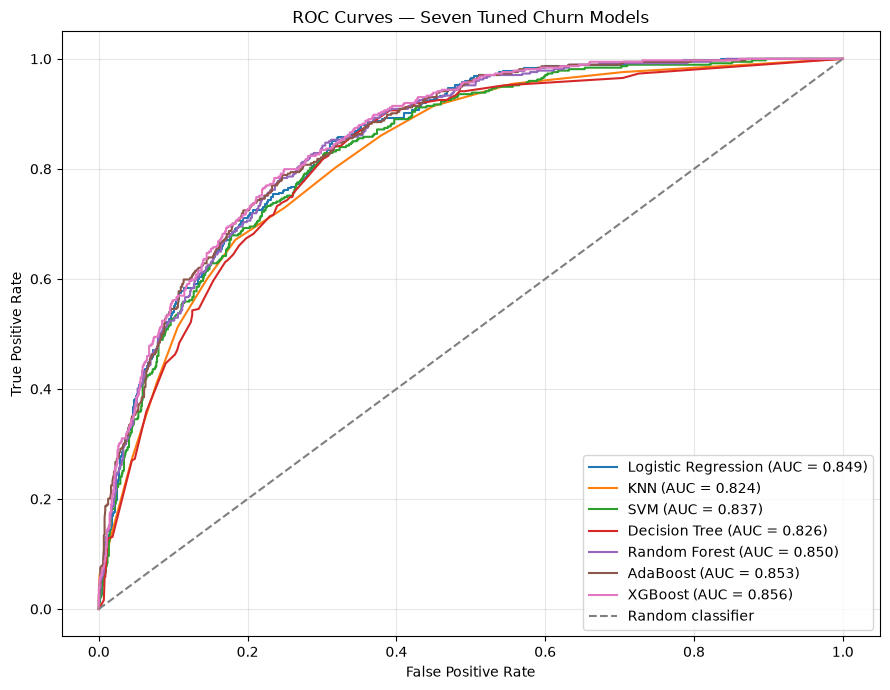

In [265]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 7))

plt.plot(
    fpr_log,
    tpr_log,
    label=f"Logistic Regression (AUC = {auc_log:.3f})"
)

plt.plot(
    fpr_knn,
    tpr_knn,
    label=f"KNN (AUC = {auc_knn:.3f})"
)

plt.plot(
    fpr_svm,
    tpr_svm,
    label=f"SVM (AUC = {auc_svm:.3f})"
)

plt.plot(
    fpr_tree,
    tpr_tree,
    label=f"Decision Tree (AUC = {auc_tree:.3f})"
)

plt.plot(
    fpr_rf,
    tpr_rf,
    label=f"Random Forest (AUC = {auc_rf:.3f})"
)

plt.plot(
    fpr_ada,
    tpr_ada,
    label=f"AdaBoost (AUC = {auc_ada:.3f})"
)

plt.plot(
    fpr_xgb,
    tpr_xgb,
    label=f"XGBoost (AUC = {auc_xgb:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves — Seven Tuned Churn Models")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 8. Model Interpretation

### 8.1. Logistic Regression coefficients

In [266]:
best_log_model = grid_log.best_estimator_

feature_names = best_log_model.named_steps["preprocessor"].get_feature_names_out()

coefficients = best_log_model.named_steps["model"].coef_[0]

coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

coef_df["Abs_Coefficient"] = coef_df["Coefficient"].abs()

coef_df = coef_df.sort_values(
    "Abs_Coefficient",
    ascending=False
)

coef_df.head(10)

,Feature,Coefficient,Abs_Coefficient
43,num__Tenure Months,-1.016784,1.016784
7,cat__Dependents_Yes,-0.769939,0.769939
6,cat__Dependents_No,0.768022,0.768022
34,cat__Contract_Month-to-month,0.690915,0.690915
36,cat__Contract_Two year,-0.612447,0.612447
14,cat__Internet Service_Fiber optic,0.351924,0.351924
45,num__Total Charges,0.296230,0.296230
41,cat__Payment Method_Electronic check,0.284858,0.284858
13,cat__Internet Service_DSL,-0.284053,0.284053
16,cat__Online Security_No,0.233347,0.233347


Higher tenure             → lower churn

Having dependents         → lower churn

Month-to-month contract   → higher churn

Two-year contract         → lower churn

Fiber optic               → higher churn

Electronic check          → higher churn

No online security        → higher churn

### 8.2. Random Forest importance

In [267]:
best_rf_model = grid_rf.best_estimator_

rf_feature_names = (
    best_rf_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

rf_importance = (
    best_rf_model
    .named_steps["model"]
    .feature_importances_
)

rf_imp_df = pd.DataFrame({
    "Feature": rf_feature_names,
    "Importance": rf_importance
}).sort_values(
    "Importance",
    ascending=False
)

rf_imp_df.head(10)

,Feature,Importance
34,cat__Contract_Month-to-month,0.124851
43,num__Tenure Months,0.102090
45,num__Total Charges,0.085226
44,num__Monthly Charges,0.058575
36,cat__Contract_Two year,0.056140
16,cat__Online Security_No,0.053458
46,num__CLTV,0.050489
14,cat__Internet Service_Fiber optic,0.043659
6,cat__Dependents_No,0.042854
25,cat__Tech Support_No,0.042642


### 8.3. Permutation Feature Importance

In [268]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    grid_rf.best_estimator_,
    X_test,
    y_test,
    scoring=f1_yes,
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

perm_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": perm.importances_mean
}).sort_values(
    "Importance",
    ascending=False
)

perm_df.head(10)

,Feature,Importance
14,Contract,0.100804
3,Dependents,0.025651
7,Internet Service,0.025205
4,Tenure Months,0.018202
18,Total Charges,0.009535
2,Partner,0.006476
1,Senior Citizen,0.003211
19,CLTV,0.003130
6,Multiple Lines,0.002583
5,Phone Service,-0.000397


### 8.4. SHAP

#### Global Feature Contributions

In [269]:
import shap

print(shap.__version__)

0.52.0


Get the trained XGBoost model

In [270]:
best_xgb_pipeline = grid_xgb.best_estimator_

Extract the preprocessor

In [271]:
xgb_preprocessor = best_xgb_pipeline.named_steps["preprocessor"]

Extract XGBoost

In [272]:
xgb_model = best_xgb_pipeline.named_steps["model"]

Transform the test data

In [273]:
X_test_processed_xgb = xgb_preprocessor.transform(X_test)

Create the SHAP Explainer

In [274]:
explainer = shap.TreeExplainer(xgb_model)

Calculate SHAP values

In [275]:
shap_values = explainer.shap_values(X_test_processed_xgb)

First visualization

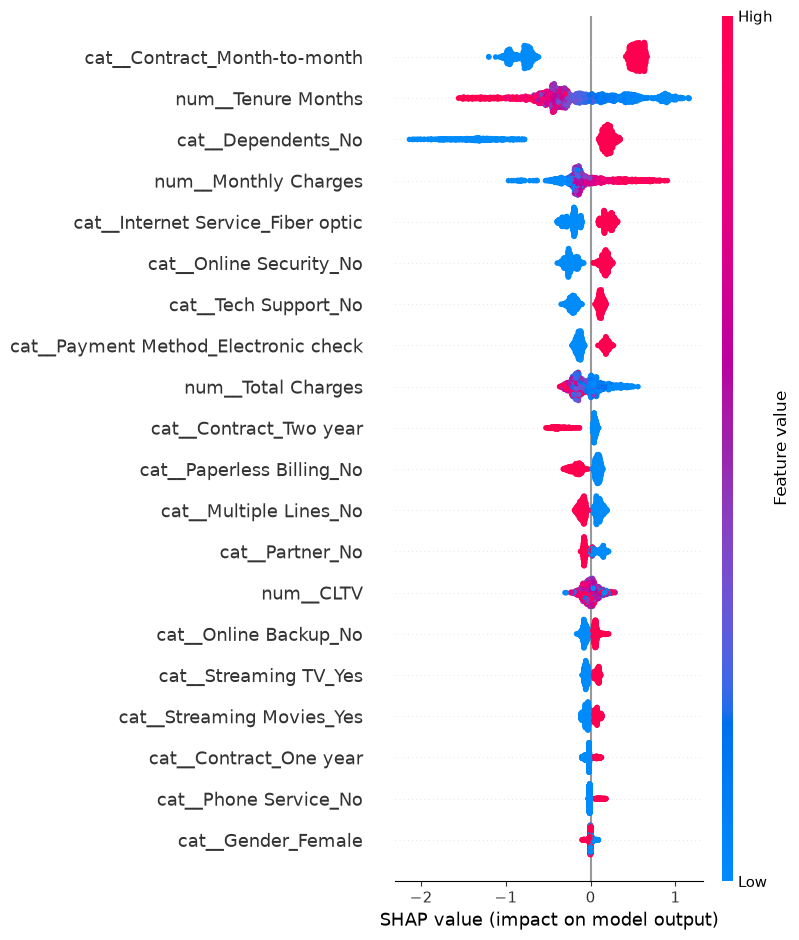

In [276]:
shap.summary_plot(
    shap_values,
    X_test_processed_xgb,
    feature_names=xgb_preprocessor.get_feature_names_out()
)

##### How to read it
- Right of 0 → pushes prediction toward churn
- Left of 0 → pushes prediction away from churn
- 🔴 Red → high feature value / category present (1)
- 🔵 Blue → low feature value / category absent (0)
- Features are ordered from most important at the top to least important at the bottom.

Also, the x-axis says SHAP value (impact on model output). These are contributions to the model's output, not direct percentage-point changes in churn probability.

| Finding                 | EDA                 | SHAP                               |
| ----------------------- | ------------------- | ---------------------------------- |
| Month-to-month contract | High churn          | Strong positive churn contribution |
| Short tenure            | Higher churn        | Strong positive contribution       |
| No dependents           | Higher churn        | Positive contribution              |
| Higher monthly charges  | Higher-risk pattern | Positive contribution              |
| Fiber optic             | High churn          | Positive contribution              |
| No online security      | High churn          | Positive contribution              |
| No tech support         | High churn          | Positive contribution              |
| Electronic check        | High churn          | Positive contribution              |
| Two-year contract       | Low churn           | Negative contribution              |


#### Individual Customer Explanation

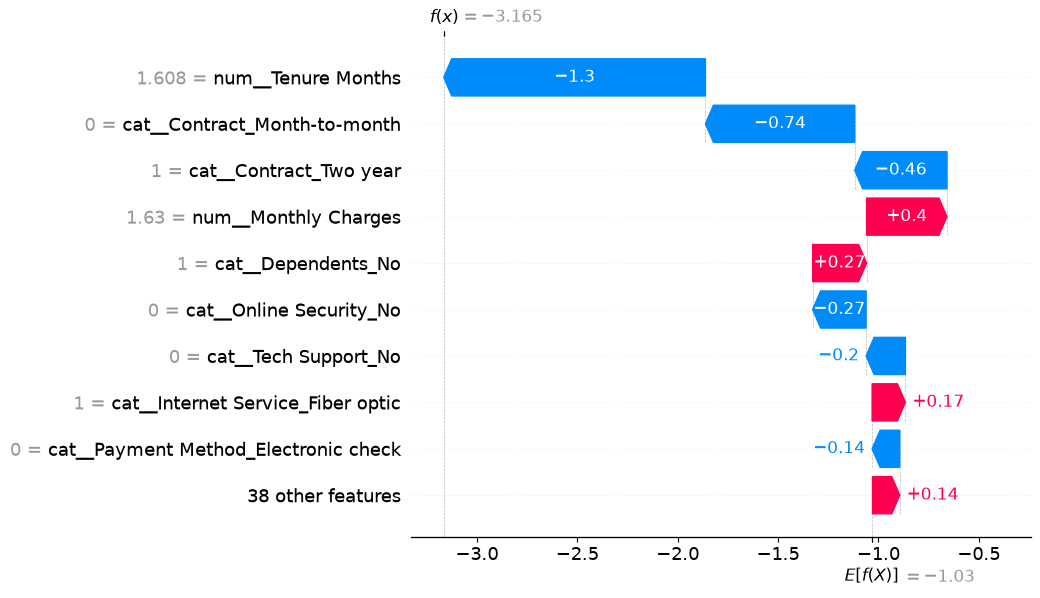

In [277]:
customer_index = 0

customer_shap = shap_values[customer_index]

shap.plots.waterfall(
    shap.Explanation(
        values=customer_shap,
        base_values=explainer.expected_value,
        data=X_test_processed_xgb[customer_index],
        feature_names=xgb_preprocessor.get_feature_names_out()
    )
)

We can summarize the customer's profile like this:

Factors reducing predicted churn

- High tenure → very strong reduction
- Not month-to-month → strong reduction
- Two-year contract → strong reduction
- Has online security → reduction
- Has tech support → reduction

Factors increasing predicted churn

- High monthly charges → moderate increase
- No dependents → moderate increase
- Fiber optic → small increase

The negative contributions clearly outweigh the positive ones.

View the actual customer's information

In [278]:
customer_profile = X_test.iloc[customer_index]

print(customer_profile)

Gender                                  Male
Senior Citizen                            No
Partner                                  Yes
Dependents                                No
Tenure Months                             72
Phone Service                            Yes
Multiple Lines                           Yes
Internet Service                 Fiber optic
Online Security                          Yes
Online Backup                            Yes
Device Protection                        Yes
Tech Support                             Yes
Streaming TV                             Yes
Streaming Movies                         Yes
Contract                            Two year
Paperless Billing                        Yes
Payment Method       Credit card (automatic)
Monthly Charges                       114.05
Total Charges                         8468.2
CLTV                                    4842
Name: 2196, dtype: object


In [279]:
customer_probability = grid_xgb.predict_proba(
    X_test.iloc[[customer_index]]
)[0, 1]

print(f"Predicted churn probability: {customer_probability:.2%}")

Predicted churn probability: 4.05%


#### Business interpretation

The customer has some characteristics associated with higher predicted churn risk — particularly high monthly charges, fiber-optic service, and having no dependents.

However, the model's strongest signals point in the opposite direction:

72 months of tenure and a two-year contract substantially reduce the predicted churn risk, with online security and tech support providing additional downward contributions.

That's why the final predicted probability is only 4.05%.

## 9. Threshold Tuning

In [280]:
import numpy as np
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

# Get churn probabilities
y_proba_rf = grid_rf.predict_proba(X_test)[:, 1]

thresholds = np.arange(0.30, 0.65, 0.05)

rows = []

for threshold in thresholds:

    # Convert probability into Yes/No prediction
    y_pred_threshold = np.where(
        y_proba_rf >= threshold,
        "Yes",
        "No"
    )

    # Confusion matrix
    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_pred_threshold,
        labels=["No", "Yes"]
    ).ravel()

    rows.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test,
            y_pred_threshold,
            pos_label="Yes"
        ),
        "Recall": recall_score(
            y_test,
            y_pred_threshold,
            pos_label="Yes"
        ),
        "F1": f1_score(
            y_test,
            y_pred_threshold,
            pos_label="Yes"
        ),
        "FP": fp,
        "FN": fn
    })

threshold_df = pd.DataFrame(rows)

print(threshold_df)

   Threshold  Precision    Recall        F1   FP   FN
0       0.30   0.453333  0.909091  0.604982  410   34
1       0.35   0.467344  0.860963  0.605833  367   52
2       0.40   0.500000  0.847594  0.628968  317   57
3       0.45   0.519031  0.802139  0.630252  278   74
4       0.50   0.538752  0.762032  0.631229  244   89
5       0.55   0.555324  0.711230  0.623681  213  108
6       0.60   0.584296  0.676471  0.627014  180  121


In [281]:
thresholds = np.arange(0.30, 0.65, 0.05)

rows = []

for threshold in thresholds:

    y_pred_threshold = np.where(
        y_proba_xgb >= threshold,
        "Yes",
        "No"
    )

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_pred_threshold,
        labels=["No", "Yes"]
    ).ravel()

    rows.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test,
            y_pred_threshold,
            pos_label="Yes"
        ),
        "Recall": recall_score(
            y_test,
            y_pred_threshold,
            pos_label="Yes"
        ),
        "F1": f1_score(
            y_test,
            y_pred_threshold,
            pos_label="Yes"
        ),
        "FP": fp,
        "FN": fn
    })

xgb_threshold_df = pd.DataFrame(rows)

print(xgb_threshold_df)

   Threshold  Precision    Recall        F1   FP   FN
0       0.30   0.543233  0.772727  0.637969  243   85
1       0.35   0.564682  0.735294  0.638792  212   99
2       0.40   0.593023  0.681818  0.634328  175  119
3       0.45   0.618280  0.614973  0.616622  142  144
4       0.50   0.670927  0.561497  0.611354  103  164
5       0.55   0.708661  0.481283  0.573248   74  194
6       0.60   0.734694  0.385027  0.505263   52  230


In [282]:
final_model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "KNN",
        "SVM",
        "Decision Tree",
        "Random Forest",
        "AdaBoost",
        "XGBoost"
    ],

    "Accuracy": [
        0.7438,
        0.7871,
        0.7999,
        0.7821,
        0.7637,
        0.8070,
        0.8105
    ],

    "Precision": [
        0.5115,
        0.5989,
        0.6429,
        0.6037,
        0.5388,
        0.6545,
        0.6709
    ],

    "Recall": [
        0.7727,
        0.5989,
        0.5535,
        0.5214,
        0.7620,
        0.5775,
        0.5615
    ],

    "F1": [
        0.6155,
        0.5989,
        0.5948,
        0.5595,
        0.6312,
        0.6136,
        0.6114
    ],

    "ROC_AUC": [
        0.8485,
        0.8245,
        0.8372,
        0.8257,
        0.8498,
        0.8527,
        0.8561
    ],

    "PR_AUC": [
        0.6442,
        0.6016,
        0.6279,
        0.5894,
        0.6560,
        0.6742,
        0.6718
    ]
})

print(final_model_comparison.round(4))

                 Model  Accuracy  Precision  Recall      F1  ROC_AUC  PR_AUC
0  Logistic Regression    0.7438     0.5115  0.7727  0.6155   0.8485  0.6442
1                  KNN    0.7871     0.5989  0.5989  0.5989   0.8245  0.6016
2                  SVM    0.7999     0.6429  0.5535  0.5948   0.8372  0.6279
3        Decision Tree    0.7821     0.6037  0.5214  0.5595   0.8257  0.5894
4        Random Forest    0.7637     0.5388  0.7620  0.6312   0.8498  0.6560
5             AdaBoost    0.8070     0.6545  0.5775  0.6136   0.8527  0.6742
6              XGBoost    0.8105     0.6709  0.5615  0.6114   0.8561  0.6718


In [283]:
percentage_cols = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1"
]

final_model_comparison[percentage_cols] = (
    final_model_comparison[percentage_cols] * 100
).round(2)

final_model_comparison["ROC_AUC"] = \
    final_model_comparison["ROC_AUC"].round(3)

final_model_comparison["PR_AUC"] = \
    final_model_comparison["PR_AUC"].round(3)

print(final_model_comparison)

                 Model  Accuracy  Precision  Recall     F1  ROC_AUC  PR_AUC
0  Logistic Regression     74.38      51.15   77.27  61.55    0.848   0.644
1                  KNN     78.71      59.89   59.89  59.89    0.824   0.602
2                  SVM     79.99      64.29   55.35  59.48    0.837   0.628
3        Decision Tree     78.21      60.37   52.14  55.95    0.826   0.589
4        Random Forest     76.37      53.88   76.20  63.12    0.850   0.656
5             AdaBoost     80.70      65.45   57.75  61.36    0.853   0.674
6              XGBoost     81.05      67.09   56.15  61.14    0.856   0.672


## 10. Customer Risk Segmentation

#### Step 1

In [284]:
test_churn_probability = grid_xgb.predict_proba(X_test)[:, 1]

print(test_churn_probability[:10])

[0.04048599 0.7924549  0.14571422 0.46572527 0.02620069 0.6556413
 0.49457294 0.07338353 0.00513187 0.35755906]


#### Step 2 — Create risk categories

Probability bands:

| Probability | Risk   |
| ----------: | ------ |
|     `< 30%` | Low    |
|    `30–60%` | Medium |
|     `≥ 60%` | High   |

These are our analytical categories, not universally established clinical/business thresholds. Later, we can change them based on the retention team's costs and objectives.

In [285]:
risk_category = np.where(
    test_churn_probability < 0.30,
    "Low",
    np.where(
        test_churn_probability < 0.60,
        "Medium",
        "High"
    )
)

print(risk_category[:10])

['Low' 'High' 'Low' 'Medium' 'Low' 'High' 'Medium' 'Low' 'Low' 'Medium']


#### Step 3 — Add risk and probability to the customer data

In [286]:
risk_df = X_test.copy()

risk_df["Churn Probability"] = test_churn_probability
risk_df["Risk Category"] = risk_category

print(risk_df.head())

      Gender Senior Citizen Partner Dependents  Tenure Months Phone Service  \
2196    Male             No     Yes         No             72           Yes   
3549  Female            Yes      No         No              8           Yes   
3515  Female             No     Yes         No             41           Yes   
5162    Male             No     Yes         No             18           Yes   
4642  Female             No     Yes         No             72           Yes   

     Multiple Lines Internet Service Online Security Online Backup  ...  \
2196            Yes      Fiber optic             Yes           Yes  ...   
3549            Yes      Fiber optic              No            No  ...   
3515            Yes              DSL             Yes           Yes  ...   
5162             No      Fiber optic              No            No  ...   
4642            Yes              DSL             Yes           Yes  ...   

     Streaming TV Streaming Movies        Contract Paperless Billing  \
21

#### Step 4 — Count the customers in each risk group

In [287]:
risk_df["Risk Category"].value_counts()

Risk Category
Low       877
Medium    336
High      196
Name: count, dtype: int64

#### Step 5 — Visualize the risk distribution

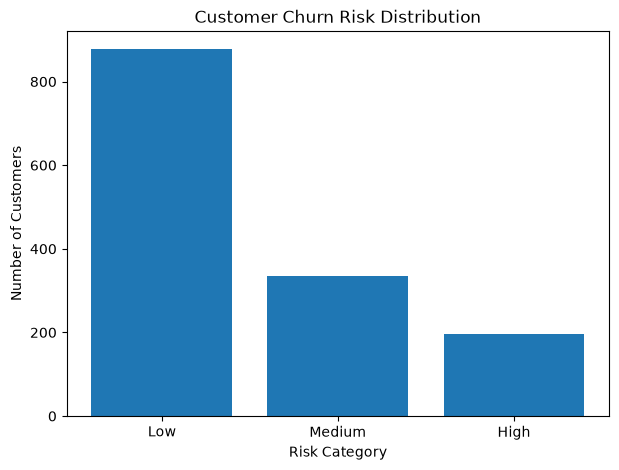

In [288]:
import matplotlib.pyplot as plt

risk_counts = risk_df["Risk Category"].value_counts()

risk_counts = risk_counts.reindex(["Low", "Medium", "High"])

plt.figure(figsize=(7, 5))

plt.bar(
    risk_counts.index,
    risk_counts.values
)

plt.xlabel("Risk Category")
plt.ylabel("Number of Customers")
plt.title("Customer Churn Risk Distribution")

plt.show()

#### Step 6 — Analyze High-Risk Customers

In [289]:
contract_risk = (
    risk_df
    .groupby("Contract")["Churn Probability"]
    .mean()
    .sort_values(ascending=False)
)

print(contract_risk)

Contract
Month-to-month    0.428371
One year          0.102216
Two year          0.035420
Name: Churn Probability, dtype: float32


Visualize this

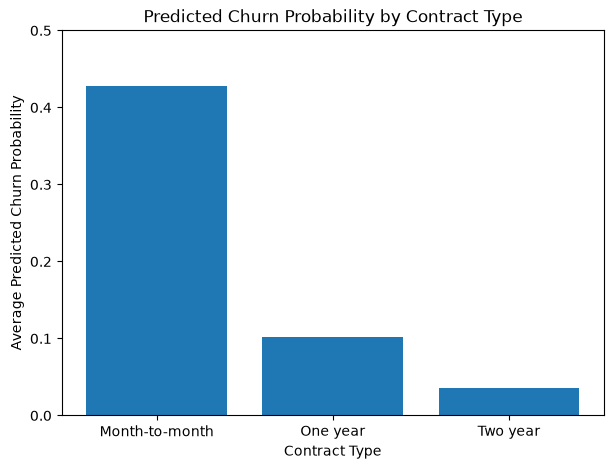

In [290]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.bar(
    contract_risk.index,
    contract_risk.values
)

plt.xlabel("Contract Type")
plt.ylabel("Average Predicted Churn Probability")
plt.title("Predicted Churn Probability by Contract Type")

plt.ylim(0, 0.5)

plt.show()

#### Step 7 — Analyze churn risk by Tenure

In [291]:
risk_df["Tenure Group"] = pd.cut(
    risk_df["Tenure Months"],
    bins=[-1, 12, 24, 36, 48, 60, 72],
    labels=[
        "0-12 months",
        "13-24 months",
        "25-36 months",
        "37-48 months",
        "49-60 months",
        "61-72 months"
    ]
)

tenure_risk = (
    risk_df
    .groupby("Tenure Group", observed=True)["Churn Probability"]
    .mean()
)

print(tenure_risk)

Tenure Group
0-12 months     0.465019
13-24 months    0.311416
25-36 months    0.210601
37-48 months    0.173777
49-60 months    0.137033
61-72 months    0.065498
Name: Churn Probability, dtype: float32


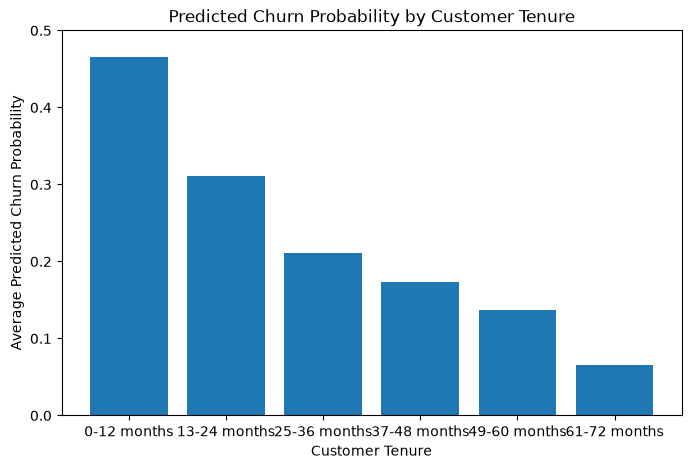

In [292]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    tenure_risk.index,
    tenure_risk.values
)

plt.xlabel("Customer Tenure")
plt.ylabel("Average Predicted Churn Probability")
plt.title("Predicted Churn Probability by Customer Tenure")

plt.ylim(0, 0.5)

plt.show()

#### Step 8 — Analyze churn risk by Internet Service

In [293]:
internet_risk = (
    risk_df
    .groupby("Internet Service")["Churn Probability"]
    .mean()
    .sort_values(ascending=False)
)

print(internet_risk)

Internet Service
Fiber optic    0.420452
DSL            0.191703
No             0.074280
Name: Churn Probability, dtype: float32


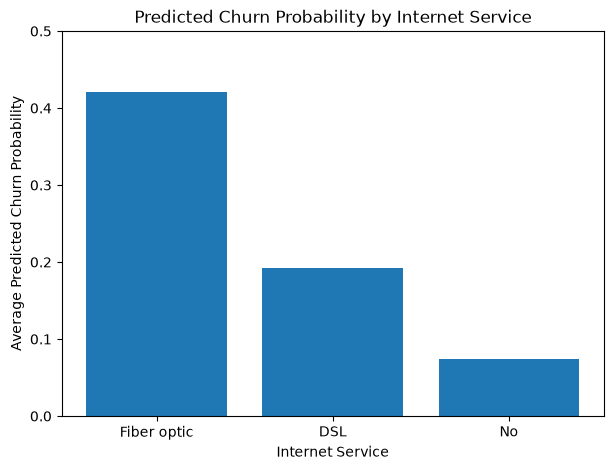

In [294]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.bar(
    internet_risk.index,
    internet_risk.values
)

plt.xlabel("Internet Service")
plt.ylabel("Average Predicted Churn Probability")
plt.title("Predicted Churn Probability by Internet Service")

plt.ylim(0, 0.5)

plt.show()

#### Step 9 — Analyze churn risk by Payment Method

In [295]:
payment_risk = (
    risk_df
    .groupby("Payment Method")["Churn Probability"]
    .mean()
    .sort_values(ascending=False)
)

print(payment_risk)

Payment Method
Electronic check             0.447409
Mailed check                 0.193134
Credit card (automatic)      0.163878
Bank transfer (automatic)    0.160084
Name: Churn Probability, dtype: float32


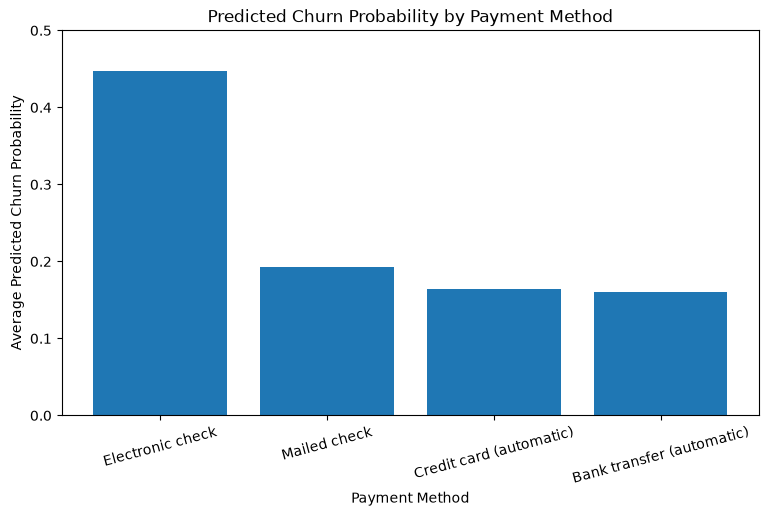

In [296]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    payment_risk.index,
    payment_risk.values
)

plt.xlabel("Payment Method")
plt.ylabel("Average Predicted Churn Probability")
plt.title("Predicted Churn Probability by Payment Method")

plt.ylim(0, 0.5)

plt.xticks(rotation=15)

plt.show()

## 11. Final Business Insights

#### 1. Contract

**Month-to-month**

- Predicted churn: 42.84%
- Observed churn: 42.71%

Longer contracts had substantially lower predicted risk.

Business interpretation: investigate whether contract flexibility, pricing, customer commitment, or other characteristics are associated with the higher risk among month-to-month customers.

#### 2. Tenure

**0–12 months**

- Predicted churn: 46.50%

**61–72 months**

- Predicted churn: 6.55%

This was one of our clearest patterns.

Business interpretation: early-tenure customers could be an important group for onboarding, engagement, and retention analysis.

#### 3. Internet Service

**Fiber optic**

- Predicted churn: 42.05%

**DSL**

- 19.17%

**No internet**

- 7.43%

Business interpretation: investigate whether pricing, service quality, customer expectations, competitive alternatives, or other factors are associated with the elevated risk in this segment.

#### 4. Payment Method

Electronic check

- Predicted churn: 44.74%

Other methods:

- Mailed check: 19.31%
- Credit card automatic: 16.39%
- Bank transfer automatic: 16.01%

Business interpretation: electronic-check customers represent another segment worth investigating for retention and payment-experience factors.

## 12. Business Recommendations

**1. Focus on early-tenure customers**

Our model predicts:

- 0–12 months: 46.50% average churn probability
- 61–72 months: 6.55%

Recommendation:
Develop a stronger early-tenure retention program, particularly during the first year. This could include onboarding support, proactive service follow-ups, and early engagement campaigns.

Why?
Newer customers represent the highest predicted-risk tenure group.

**2. Investigate month-to-month customers**

Month-to-month customers have an average predicted churn probability of 42.84%, compared with:

- One year: 10.22%
- Two year: 3.54%

Recommendation:
Analyze why month-to-month customers are more likely to be at risk and consider targeted retention offers, contract incentives, or service improvements where appropriate.

Important: We should investigate the underlying reasons rather than assume that contract length itself causes churn.

**3. Investigate the fiber-optic segment**

Fiber-optic customers have an average predicted churn probability of 42.05%, considerably higher than DSL customers at 19.17%.

Recommendation:
Investigate this segment for factors such as:

- Pricing
- Service quality
- Customer expectations
- Technical issues
- Competitive alternatives
- Customer support experience

**4. Examine electronic-check customers**

Electronic-check customers have an average predicted churn probability of 44.74%, compared with approximately 16–19% for the other payment methods.

Recommendation:
Investigate whether the electronic-check segment is associated with specific customer characteristics or payment-related experiences. If appropriate, the company could test alternative payment options or targeted communication around billing.

Again, we shouldn't conclude that the payment method itself causes churn.

**5. Use predicted risk for targeted retention**

Our model classified the 1,409 test customers into:

- 877 Low risk — 62.24%
- 336 Medium risk — 23.85%
- 196 High risk — 13.91%

Recommendation:
Instead of treating every customer equally, a company could use predicted churn probability to prioritize high-risk customers for retention analysis or intervention.

For example:

| Risk   | Possible approach                     |
| ------ | ------------------------------------- |
| Low    | Normal customer engagement            |
| Medium | Monitor and investigate               |
| High   | Prioritize for retention intervention |

The exact thresholds should ultimately be determined using business costs and validation data, rather than treating 30% and 60% as universal standards.

## 13. Project Limitations

**1. Class imbalance**

Only about 26.5% of customers churned, while about 73.5% did not.

We addressed this by:

- Using a stratified train-test split
- Using churn-class F1 for hyperparameter tuning
- Allowing class_weight="balanced" during tuning for applicable models
- Evaluating Precision, Recall, F1, ROC-AUC and PR-AUC rather than accuracy alone

However, we did not use SMOTE or undersampling.

**2. Association does not mean causation**

Our analysis found strong relationships such as:

- Month-to-month → higher predicted risk
- Short tenure → higher predicted risk
- Fiber optic → higher predicted risk
- Electronic check → higher predicted risk

But the dataset is observational.

Therefore, we cannot say these factors cause churn.

For example:

_"Fiber optic causes customers to churn."_

would be an unjustified conclusion.

Instead:

_"Fiber-optic customers show higher predicted churn risk."_

is appropriate.

**3. Single dataset**

Our analysis uses 7,043 customer records from one telecom dataset.

Therefore, we don't know whether the same model performance would hold for:

- another telecom company
- another geographic market
- a different time period
- future customers

External or future-data validation would be needed before deployment.

**4. Missing business variables**

The dataset doesn't contain many potentially useful real-world variables, such as:

- Customer complaints
- Network outages
- Customer satisfaction
- Number of support interactions
- Competitor offers
- Pricing changes
- Actual service usage
- Call/data consumption
- Customer engagement history

Including such variables could potentially improve the usefulness of a production churn model.

**5. Threshold selection**

Our default classification threshold was 0.50.

We also explored different thresholds and saw the expected trade-off:

_Lower threshold → higher recall but more false positives_

_Higher threshold → higher precision but more false negatives_

For example, with XGBoost:

- 0.35 threshold → 73.53% recall, 56.47% precision
- 0.50 threshold → 56.15% recall, 67.09% precision

A real company should choose the threshold based on the cost of false positives vs. missed churners.

Also, our threshold exploration on the held-out test set should be considered exploratory; for a production workflow, the threshold should be selected using validation/CV data and the final test set should remain untouched for evaluation.

## 14. Conclusion

This project developed an end-to-end machine learning pipeline for analyzing and predicting customer churn using a telecom customer dataset containing 7,043 customer records. The analysis covered data cleaning, exploratory data analysis, feature preparation, stratified train-test splitting, categorical encoding, numerical feature scaling, model development, hyperparameter tuning, evaluation, model interpretation, and customer risk segmentation.

Seven classification algorithms were evaluated: Logistic Regression, K-Nearest Neighbors, Support Vector Machine, Decision Tree, Random Forest, AdaBoost, and XGBoost. Hyperparameters were optimized using 5-fold cross-validation, with the churn-class F1-score used as the primary tuning metric. Model performance was evaluated using Accuracy, Precision, Recall, F1-score, ROC-AUC, PR-AUC, and confusion matrices.

At the default 0.50 classification threshold, XGBoost achieved the highest accuracy (81.05%) and ROC-AUC (0.856) among the tested models, while Random Forest achieved the highest F1-score (63.12%) and Logistic Regression achieved the highest churn recall (77.27%). These results demonstrate that model performance depends on the evaluation metric and the business objective rather than on a single universal measure of performance.

Model interpretation using feature importance, permutation importance, and SHAP identified factors such as contract type, tenure, dependents, internet service, monthly charges, total charges, online security, technical support, and payment method as important contributors to churn predictions. Risk segmentation further showed that customers with shorter tenure, month-to-month contracts, fiber-optic internet service, and electronic-check payment methods had higher average predicted churn probabilities.

The XGBoost model was also used to segment customers according to predicted churn probability. Using the selected analytical risk thresholds, 62.24% of the test customers were classified as low risk, 23.85% as medium risk, and 13.91% as high risk. This demonstrates how a churn model can move beyond prediction and support customer-level risk prioritization.

The findings represent predictive associations rather than causal relationships. The analysis is based on a single dataset and does not include several potentially important business variables such as customer complaints, service outages, satisfaction, usage behavior, and competitor activity. Therefore, external or future-data validation would be required before deploying the model in a real-world environment.

Overall, the project demonstrates how machine learning can be applied to customer churn analysis to identify patterns, estimate individual customer risk, interpret important predictive factors, and support data-driven retention analysis.
